# Lab 7: Trees, Forests and Boosting — Solutions

In this lab we build a decision tree from scratch and grow a random forest from it, for classification. Gradient boosting (for classification and for regression), XGBoost (its leaf values, checked against the real library), LightGBM and CatBoost are homework.

The homework needs `xgboost`, `lightgbm` and `catboost` (`pip install xgboost lightgbm catboost`).

In [1]:
%matplotlib inline
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
plt.style.use("seaborn-v0_8")

## Helpers

The functions below are given: run the two cells and move on. `load_moons`, `make_wave`, `make_tabular` and `make_cat_data` simulate the data of the lab, `accuracy` scores predictions, `sigmoid` turns log-odds into a probability, and `plot_regions` draws the regions of a classifier.

In [2]:
def load_moons(n_per, noise=0.3, seed=0):
    """Two interleaved moons: X, a (2 n_per, 2) array of points, and y, their labels 0 or 1."""
    rng = np.random.RandomState(seed)
    t1 = rng.uniform(0, np.pi, n_per)
    t0 = rng.uniform(0, np.pi, n_per)
    # class 1 is the upper half of the unit circle, class 0 the lower half, shifted
    X1 = np.column_stack([np.cos(t1), np.sin(t1)])
    X0 = np.column_stack([1 - np.cos(t0), 0.5 - np.sin(t0)])
    X = np.concatenate([X1, X0]) + noise * rng.randn(2 * n_per, 2)
    y = np.concatenate([np.ones(n_per, dtype=int), np.zeros(n_per, dtype=int)])
    return X, y


def make_wave(n, noise=0.3, seed=0):
    """A noisy sine: X, a (n, 1) array of positions, and y, the values sin(x) + noise."""
    rng = np.random.RandomState(seed)
    x = rng.uniform(-np.pi, np.pi, n)
    return x.reshape(-1, 1), np.sin(x) + noise * rng.randn(n)


def make_tabular(n, n_columns=10, decay=0.7, seed=0):
    """A table: X, a (n, n_columns) array, and y, labels 0 or 1; every column carries less signal than the previous one."""
    rng = np.random.RandomState(seed)
    weights = decay ** np.arange(n_columns)
    X = rng.randn(n, n_columns)
    y = (X @ weights + 0.5 * rng.randn(n) > 0).astype(int)
    return X, y


def make_cat_data(n, n_categories, seed=0):
    """Three numeric columns X, a categorical column cat (think customer id) with no information, and labels y."""
    rng = np.random.RandomState(seed)
    X = rng.randn(n, 3)
    y = (1.5 * X[:, 0] + rng.randn(n) > 0).astype(int)
    cat = rng.randint(0, n_categories, n)
    return X, cat, y

In [3]:
def accuracy(y_pred, y):
    """Share of the labels y_pred that are equal to the true labels y."""
    return np.mean(y_pred == y)


def sigmoid(F):
    """Probability 1 / (1 + exp(-F)) for the log-odds F."""
    return 1 / (1 + np.exp(-F))


def plot_regions(ax, predict, X, y, title="", margin=0.5):
    """Draw the (n, 2) points X with labels y on ax, and the regions of the classifier predict."""
    # the predicted label on a fine grid of the plane
    grid_1 = np.linspace(X[:, 0].min() - margin, X[:, 0].max() + margin, 200)
    grid_2 = np.linspace(X[:, 1].min() - margin, X[:, 1].max() + margin, 200)
    G1, G2 = np.meshgrid(grid_1, grid_2)
    labels = predict(np.column_stack([G1.ravel(), G2.ravel()])).reshape(G1.shape)
    ax.contourf(G1, G2, labels, levels=[-0.5, 0.5, 1.5], colors=["royalblue", "crimson"], alpha=0.15)
    # the points
    ax.scatter(X[y == 1, 0], X[y == 1, 1], color="crimson", s=12)
    ax.scatter(X[y == 0, 0], X[y == 0, 1], color="royalblue", s=12)
    ax.set_title(title)

## 1. Decision tree

**The data.** Two interleaved moons: every point $x_i$ has 2 columns, and a label $y_i$ equal to 0 or 1. The training set has 300 points, and the test set 1000.

**What a tree is.** A sequence of yes/no questions of the form "is $x_{ij} \le t$?", on one column $j$ with one threshold $t$ (lecture: "A tree is a sequence of questions"). The rows that answer yes go to the left child, the others to the right child. A node that asks no question is a **leaf**, and it predicts the majority class of its rows.

**What we compute at every node:**
- the **Gini impurity** of the labels $y$ of the node, with $p_k$ the proportion of class $k$ in the node. It is the probability that two rows drawn at random from the node have different classes: $p_k^2$ is the probability that both are of class $k$, so $\sum_k p_k^2$ is the probability that they agree. It is 0 for a pure node, and 0.5 for a 50/50 node:
$$
G(y) = 1 - \sum_{k} p_k^2 ;
$$
- the **weighted impurity** of a split: the impurity of the two children together, where each child counts for its share of the rows ($n$ rows in the node, $n_L$ in the left child and $n_R$ in the right child):
$$
I_{\text{split}} = \frac{n_L}{n} G(y_L) + \frac{n_R}{n} G(y_R) ;
$$
- the **gain** of the split: how much impurity the question removes. The best question has the largest gain:
$$
\text{gain} = G(y) - I_{\text{split}} .
$$

**How to grow the tree:**
1. **Stop:** if the node is pure, or if its depth is `max_depth`, it becomes a leaf.
2. **Best question:** try every column $j$ (every feature) and every threshold $t$, and keep the largest gain. Between two neighbouring values of a column, every threshold gives the same split, so we try one threshold per gap: the midpoint. For the values 1, 2 and 4, the thresholds are 1.5 and 3. If no split has a positive gain, the node becomes a leaf.
3. **Children:** otherwise, store the question and grow the two children, one level deeper.

In the code, a node is a dictionary, so the whole tree is one nested object:
```python
{"leaf": True, "value": 0}
{"leaf": False, "column": 1, "threshold": 0.337, "left": {...}, "right": {...}}
```

**Exercise 1.** Complete `DecisionTree`: `gini`, `best_split` and `fit`, which grows the tree with the three steps above. `predict` is given.

In [4]:
class DecisionTree:
    """Decision tree for classification, grown node by node."""

    def __init__(self, max_depth=3, max_features=None, seed=0):
        self.max_depth = max_depth          # a node at this depth becomes a leaf
        self.max_features = max_features    # features tried at every node, None for all of them (used by the forest)
        self.rng = np.random.RandomState(seed)

    def gini(self, y):
        """Gini impurity G(y) = 1 - sum_k p_k^2 of the labels y of one node."""
        _, counts = np.unique(y, return_counts=True)
        p = counts / len(y)                  # p_k, the proportion of class k
        return 1 - np.sum(p ** 2)

    def best_split(self, X, y):
        """Best question "x_j <= t" of one node: returns (j, t, gain), or (None, None, 0.0) if no question has a positive gain."""
        # the features to try: all of them, or max_features of them drawn at random (for the forest)
        d = X.shape[1]
        columns = np.arange(d) if self.max_features is None else self.rng.choice(d, self.max_features, replace=False)
        n = len(y)
        G = self.gini(y)                                    # impurity of the node
        best_j, best_t, best_gain = None, None, 0.0         # the best question found so far: none yet
        for j in columns:                                   # every feature
            values = np.unique(X[:, j])                     # its distinct values, sorted
            for t in (values[:-1] + values[1:]) / 2:        # every threshold: the midpoints between neighbours
                left = X[:, j] <= t                         # the rows that answer yes
                y_left, y_right = y[left], y[~left]
                I_split = len(y_left) / n * self.gini(y_left) + len(y_right) / n * self.gini(y_right)
                gain = G - I_split
                if gain > best_gain:
                    best_j, best_t, best_gain = j, t, gain
        return best_j, best_t, best_gain

    def fit(self, X, y, depth=0):
        """Grow the node holding the rows (X, y): a leaf, or a question with its two children."""
        # step 1: a leaf with the majority class, kept if the node is too deep or pure
        node = {"leaf": True, "value": np.bincount(y).argmax()}
        if depth < self.max_depth and self.gini(y) > 0:
            # step 2: the best question; a node where no question helps stays a leaf
            j, t, gain = self.best_split(X, y)
            if j is not None:
                # step 3: store the question, and grow the two children one level deeper
                left = X[:, j] <= t
                node = {"leaf": False, "column": j, "threshold": t,
                        "left": self.fit(X[left], y[left], depth + 1),
                        "right": self.fit(X[~left], y[~left], depth + 1)}
        if depth == 0:
            self.root_ = node      # the whole tree
        return node

    # ---- given ----
    def predict(self, X, node=None):
        """Prediction for every row of X: a question sends its rows to its two children, a leaf answers."""
        node = self.root_ if node is None else node
        if node["leaf"]:
            return np.full(len(X), node["value"], dtype=float)
        left = X[:, node["column"]] <= node["threshold"]
        prediction = np.zeros(len(X))
        prediction[left] = self.predict(X[left], node["left"])
        prediction[~left] = self.predict(X[~left], node["right"])
        return prediction

**Check your tree.** First on small cases where we know the answer, then on the moons with a tree of depth 3, against scikit-learn. You should get the same accuracies as scikit-learn (train 90.7%, test 87.8%) and the same first question (column 1, threshold 0.238). The regions are straight cuts parallel to the axes, because every question looks at one column only.

Gini of a pure node:  0.0 (expected 0.0)
Gini of a 50/50 node: 0.5 (expected 0.5)
Gini of a 90/10 node: 0.18 (expected 0.18)
Signal in column 1: column 1, threshold 3.0, gain 0.5 (expected 1, 3.0, 0.5)
Ours:    train 90.7%, test 87.8%, first question: column 1, threshold 0.238
sklearn: train 90.7%, test 87.8%, first question: column 1, threshold 0.238


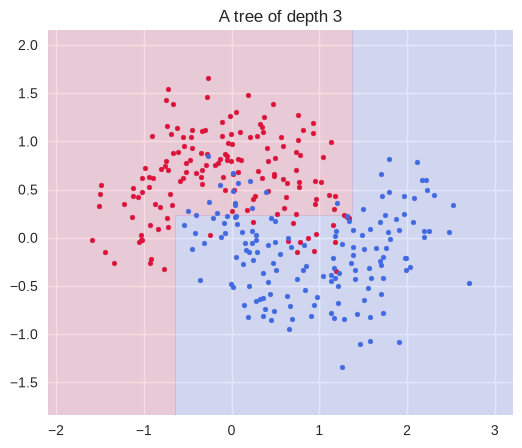

In [5]:
tree = DecisionTree()
print("Gini of a pure node: ", tree.gini(np.array([1, 1, 1, 1])), "(expected 0.0)")
print("Gini of a 50/50 node:", tree.gini(np.array([0, 1, 0, 1])), "(expected 0.5)")
print("Gini of a 90/10 node:", round(tree.gini(np.array([0] * 9 + [1])), 2), "(expected 0.18)")
column, threshold, gain = tree.best_split(np.array([[0., 5.], [1., 1.], [2., 5.], [3., 1.]]), np.array([1, 0, 1, 0]))
print(f"Signal in column 1: column {column}, threshold {threshold}, gain {gain} (expected 1, 3.0, 0.5)")

X_moons, y_moons = load_moons(150, seed=0)
X_moons_test, y_moons_test = load_moons(500, seed=1)
tree_3 = DecisionTree(max_depth=3)
tree_3.fit(X_moons, y_moons)
sk_tree = DecisionTreeClassifier(max_depth=3, random_state=0).fit(X_moons, y_moons)
print(f"Ours:    train {accuracy(tree_3.predict(X_moons), y_moons):.1%}, test {accuracy(tree_3.predict(X_moons_test), y_moons_test):.1%}, "
      f"first question: column {tree_3.root_['column']}, threshold {tree_3.root_['threshold']:.3f}")
print(f"sklearn: train {sk_tree.score(X_moons, y_moons):.1%}, test {sk_tree.score(X_moons_test, y_moons_test):.1%}, "
      f"first question: column {sk_tree.tree_.feature[0]}, threshold {sk_tree.tree_.threshold[0]:.3f}")

fig, ax = plt.subplots(figsize=(6, 5))
plot_regions(ax, tree_3.predict, X_moons, y_moons, "A tree of depth 3")
plt.show()

**The depth is the capacity knob** (lecture: "Depth is the capacity knob", "And they over-fit"). One tree for every depth: the training accuracy keeps rising and reaches 100% at depth 9, while the test accuracy stays around 87% from depth 2 on. At depth 12 the regions have thin stripes around single training points: the tree is learning the noise.

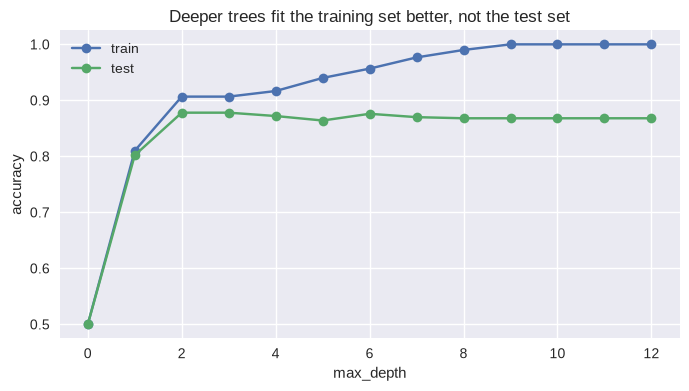

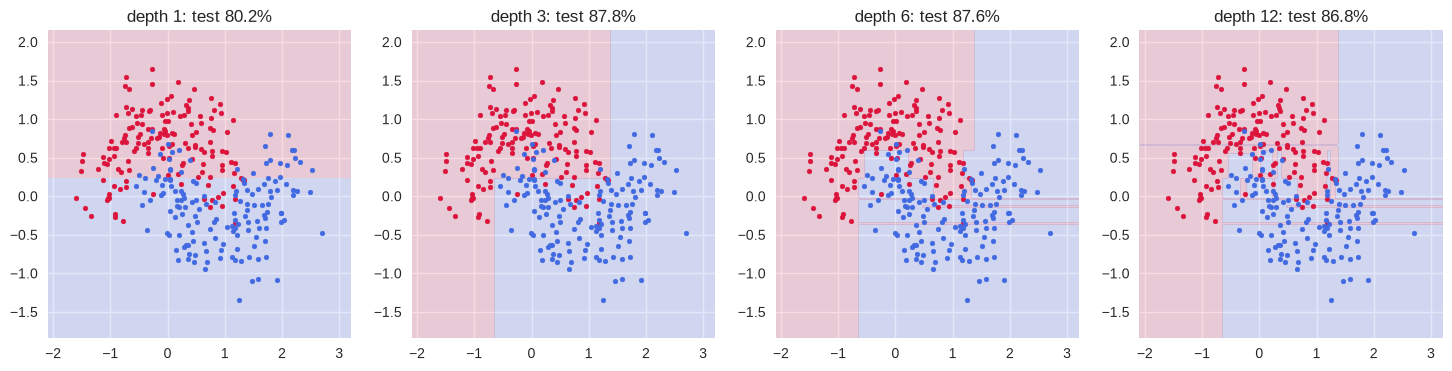

In [6]:
depths = list(range(0, 13))
train_scores, test_scores = [], []
for depth in depths:
    tree_d = DecisionTree(max_depth=depth)
    tree_d.fit(X_moons, y_moons)
    train_scores.append(accuracy(tree_d.predict(X_moons), y_moons))
    test_scores.append(accuracy(tree_d.predict(X_moons_test), y_moons_test))

plt.figure(figsize=(8, 4))
plt.plot(depths, train_scores, marker="o", label="train")
plt.plot(depths, test_scores, marker="o", label="test")
plt.xlabel("max_depth")
plt.ylabel("accuracy")
plt.title("Deeper trees fit the training set better, not the test set")
plt.legend()
plt.show()

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, depth in zip(axes, [1, 3, 6, 12]):
    tree_d = DecisionTree(max_depth=depth)
    tree_d.fit(X_moons, y_moons)
    score = accuracy(tree_d.predict(X_moons_test), y_moons_test)
    plot_regions(ax, tree_d.predict, X_moons, y_moons, f"depth {depth}: test {score:.1%}")
plt.show()

**The real problem: instability** (lecture: "The real problem: instability"). Change the training data a little, and the tree changes a lot. Below, three trees of depth 3, each grown on a bootstrap sample: 300 rows drawn with replacement from the same training set. Their accuracy is similar, but they are not the same tree. Their first question moves from 0.09 to 0.50, and two of them disagree on up to 12% of the test points. A random forest fixes this by letting many such trees vote.

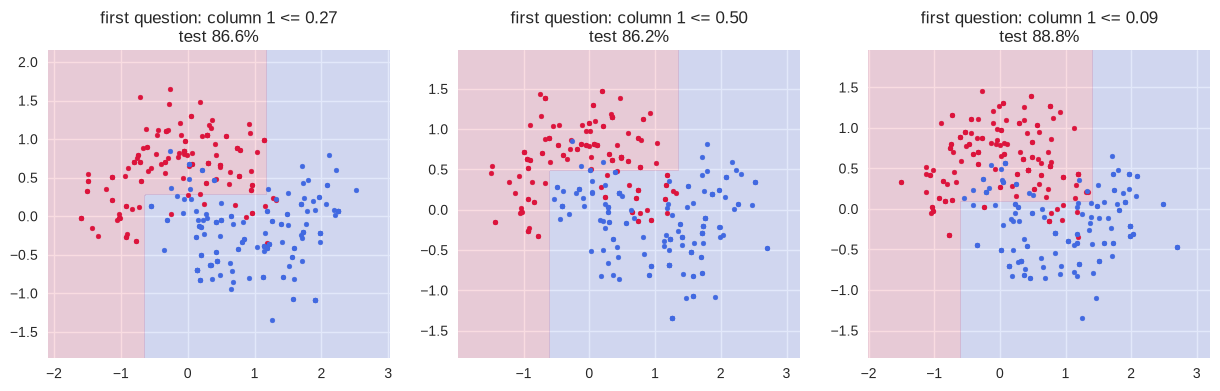

Trees 1 and 2 disagree on 6% of the test points
Trees 1 and 3 disagree on 7% of the test points
Trees 2 and 3 disagree on 12% of the test points


In [7]:
rng = np.random.RandomState(3)
trees = []
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax in axes:
    rows = rng.choice(len(X_moons), len(X_moons))     # a bootstrap sample of the training set
    tree_b = DecisionTree(max_depth=3)
    tree_b.fit(X_moons[rows], y_moons[rows])
    trees.append(tree_b)
    score = accuracy(tree_b.predict(X_moons_test), y_moons_test)
    plot_regions(ax, tree_b.predict, X_moons[rows], y_moons[rows],
                 f"first question: column {tree_b.root_['column']} <= {tree_b.root_['threshold']:.2f}\ntest {score:.1%}")
plt.show()

for a, b in [(0, 1), (0, 2), (1, 2)]:
    disagree = np.mean(trees[a].predict(X_moons_test) != trees[b].predict(X_moons_test))
    print(f"Trees {a + 1} and {b + 1} disagree on {disagree:.0%} of the test points")

## 2. Random forest

**The idea.** Grow many deep trees and let them vote, so that their instability cancels out. Why it works (lecture: "Trees must disagree"):
$$
\text{Var}(\bar f) = \frac{\sigma^2}{M} + \frac{M-1}{M} \, \rho \, \sigma^2 ,
$$
- $\sigma^2$: how much **one tree** changes from one dataset to another (its instability);
- $M$: the number of trees;
- $\rho$: how **similar** two trees are, from 0 (completely different) to 1 (identical);
- $\text{Var}(\bar f)$: how much **the vote of the forest** changes. We want it small.

The first term shrinks when we add trees, the second one does not. With $\sigma^2 = 1$ and $M = 100$ trees: if the trees are completely different ($\rho = 0$), the variance falls to 0.01; if they are identical ($\rho = 1$), it stays at 1, as for a single tree. It is like asking 100 people for their opinion: if they all copy each other, it is like asking one person. So the trees must disagree, and two sources of randomness make them disagree:
- **bootstrap:** every tree sees its own $n$ rows, drawn with replacement;
- **`max_features`:** at **every node**, a tree tries only `max_features` columns, drawn at random. That is the first line of `best_split`.

**How to fit it:** for every tree $m = 1, \dots, M$, draw the bootstrap rows, and grow a tree on these rows.

**How to predict:** the **majority vote** of the trees. With the labels 0 and 1, the prediction is 1 when the mean of the votes is at least 0.5.

**Exercise 2.** Complete `RandomForest`: `fit` and `predict`.

In [8]:
class RandomForest:
    """Random forest: deep trees on bootstrap resamples, and a majority vote."""

    def __init__(self, n_trees=100, max_depth=8, max_features=None, seed=0):
        self.n_trees = n_trees              # number of trees M
        self.max_depth = max_depth          # depth of every tree
        self.max_features = max_features    # columns tried at every node, None for all of them
        self.seed = seed                    # seed of the bootstrap

    def fit(self, X, y):
        """Grow n_trees trees, each on its own bootstrap resample of the rows."""
        rng = np.random.RandomState(self.seed)
        n = len(X)
        self.trees_ = []
        for m in range(self.n_trees):
            rows = rng.choice(n, n)          # bootstrap: n rows drawn with replacement
            tree = DecisionTree(self.max_depth, self.max_features, seed=m)
            tree.fit(X[rows], y[rows])
            self.trees_.append(tree)
        return self

    def predict(self, X, m=None):
        """Majority vote of the first m trees (of all of them when m is None)."""
        votes = np.array([tree.predict(X) for tree in self.trees_[:m]])   # (m, n): the vote of every tree for every point
        return (np.mean(votes, axis=0) >= 0.5).astype(int)

**A forest on the moons:** 100 trees of depth 8 (this takes a little while, every tree is grown by your own code). The vote of 100 trees reaches 90.2% on the test set, above the 87.8% of the tree of depth 3, although every tree of the forest is deep enough to over-fit. The accuracy is noisy, but it levels off around 90% and does not fall as trees are added (lecture: "More trees never over-fits").

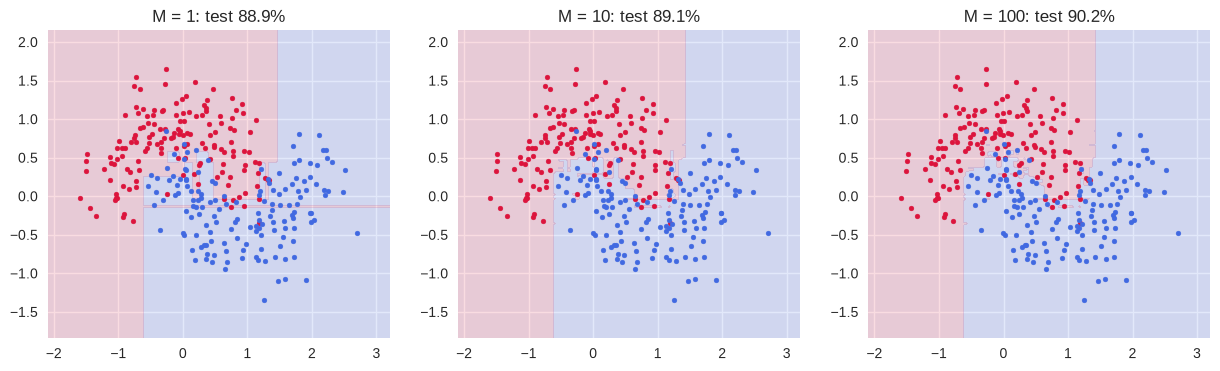

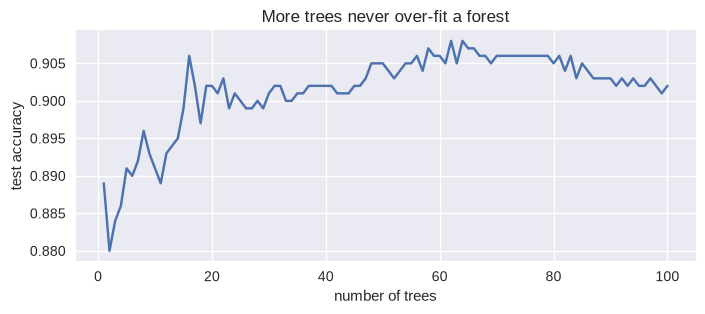

In [9]:
forest = RandomForest(n_trees=100, max_depth=8).fit(X_moons, y_moons)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, m in zip(axes, [1, 10, 100]):
    score = accuracy(forest.predict(X_moons_test, m), y_moons_test)
    plot_regions(ax, lambda X: forest.predict(X, m), X_moons, y_moons, f"M = {m}: test {score:.1%}")
plt.show()

n_trees = list(range(1, 101))
forest_scores = [accuracy(forest.predict(X_moons_test, m), y_moons_test) for m in n_trees]
plt.figure(figsize=(8, 3))
plt.plot(n_trees, forest_scores)
plt.xlabel("number of trees")
plt.ylabel("test accuracy")
plt.title("More trees never over-fit a forest")
plt.show()

**The knob: `max_features`** (lecture: "The knob: max_features", "Strength against diversity"). The moons have only 2 columns, so we use a table of 10 columns, with 200 rows to train on, and forests of 20 trees of depth 6. Every forest beats the single tree (74.1%). With `max_features` = 1 the trees disagree the most (correlation 0.10) but each of them is weak: 75.1%. With all 10 columns they are strong but alike (correlation 0.44): 81.9%. The best value is in between: 5 columns, 82.9%.

A single tree of depth 6: test 74.1%


max_features  1: test 75.1%, correlation 0.10


max_features  2: test 77.3%, correlation 0.17


max_features  3: test 80.5%, correlation 0.22


max_features  5: test 82.9%, correlation 0.33


max_features 10: test 81.9%, correlation 0.44


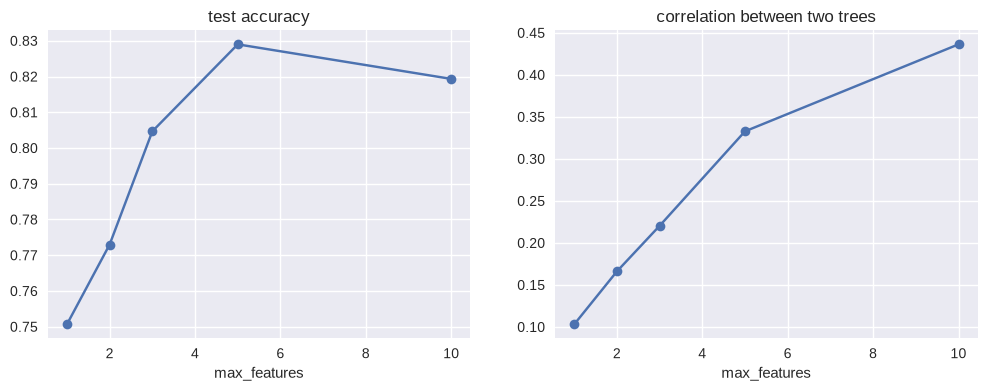

In [10]:
X_tab, y_tab = make_tabular(200, seed=0)
X_tab_test, y_tab_test = make_tabular(3000, seed=1)

tree_tab = DecisionTree(max_depth=6)
tree_tab.fit(X_tab, y_tab)
print(f"A single tree of depth 6: test {accuracy(tree_tab.predict(X_tab_test), y_tab_test):.1%}")

features = [1, 2, 3, 5, 10]
scores, correlations = [], []
for max_features in features:
    forest_k = RandomForest(n_trees=20, max_depth=6, max_features=max_features).fit(X_tab, y_tab)
    scores.append(accuracy(forest_k.predict(X_tab_test), y_tab_test))
    # the correlations between all pairs of trees, without the 1 of the diagonal
    votes = np.array([tree.predict(X_tab_test) for tree in forest_k.trees_])
    rho = np.corrcoef(votes)
    correlations.append((np.sum(rho) - 20) / (20 * 19))
    print(f"max_features {max_features:2d}: test {scores[-1]:.1%}, correlation {correlations[-1]:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(features, scores, marker="o")
axes[0].set_xlabel("max_features")
axes[0].set_title("test accuracy")
axes[1].plot(features, correlations, marker="o")
axes[1].set_xlabel("max_features")
axes[1].set_title("correlation between two trees")
plt.show()

## Homework

The homework needs `xgboost`, `lightgbm` and `catboost`.

### Gradient boosting

**The idea.** A forest averages deep trees, grown independently. Boosting **adds up** shallow trees, grown one after the other: each new tree corrects what the sum of the previous ones still gets wrong (lecture: "Combine many trees differently", "Forest and boosting attack different errors"). We use the same moons.

**The model** (lecture: "Boosting as an additive model"). For every point, a number $F(x)$, the **log-odds** of class 1, which the sigmoid $\sigma(F) = 1 / (1 + e^{-F})$ turns into a probability. $F$ is a sum of $M$ trees $h_m$, each one shrunk by the **learning rate** $\eta$:
$$
F_M(x) = F_0 + \eta \, h_1(x) + \dots + \eta \, h_M(x) .
$$

**How to fit it.** Start from the log-odds of $p_0$, the share of class 1:
$$
F_0 = \log \frac{p_0}{1 - p_0} . \qquad \text{(1)}
$$
Then repeat $M$ times: compute the residuals, how far each probability is from its label,
$$
r_i = y_i - \sigma(F(x_i)) , \qquad \text{(2)}
$$
fit a shallow regression tree $h_m$ to the residuals (3), and add it:
$$
F \leftarrow F + \eta \, h_m(x) . \qquad \text{(4)}
$$
The prediction is class 1 when $\sigma(F_M(x)) > 0.5$ (5).

The trees are **regression** trees, even for classification: each one predicts a number, a correction of $F$, not a class (we use scikit-learn's `DecisionTreeRegressor`). The residual $y_i - \sigma(F(x_i))$ is minus the gradient of the log loss, which is why this is called *gradient* boosting (lecture: "Boosting is gradient descent in function space"). Nothing is ever revised, every tree only adds something on top, so the sum of the first $m$ trees is a model too.

**Exercise 3 (homework).** Complete `GradientBoosting`: `fit` and `predict`.

In [11]:
class GradientBoosting:
    """Gradient boosting for classification: F holds log-odds, and every shallow regression tree corrects the sum so far."""

    def __init__(self, n_trees=100, eta=1.0, max_depth=2):
        self.n_trees = n_trees          # number of trees M
        self.eta = eta                  # learning rate
        self.max_depth = max_depth      # depth of every tree

    def fit(self, X, y):
        """Fit the n_trees trees, one after the other."""
        p0 = np.mean(y)
        self.F0_ = np.log(p0 / (1 - p0))                                         # (1)
        F = np.full(len(y), self.F0_)
        self.trees_ = []
        for _ in range(self.n_trees):
            r = y - sigmoid(F)                                                   # (2)
            tree = DecisionTreeRegressor(max_depth=self.max_depth).fit(X, r)    # (3)
            F = F + self.eta * tree.predict(X)                                   # (4)
            self.trees_.append(tree)
        return self

    def predict(self, X, m=None):
        """Labels 0 or 1, from F_0 plus the first m trees (all of them when m is None)."""
        F = np.full(len(X), self.F0_)
        for tree in self.trees_[:m]:
            F = F + self.eta * tree.predict(X)
        return (sigmoid(F) > 0.5).astype(int)                                    # (5)

**Boosting on the moons:** 100 trees of depth 2, with $\eta = 1$, and the sum of the first 1, 10, 50 and 100 trees, with no refitting. The first tree alone is a plain tree of depth 2 (87.8%). Then the sum slowly bends to the moons, and reaches 90.9% with 100 trees.

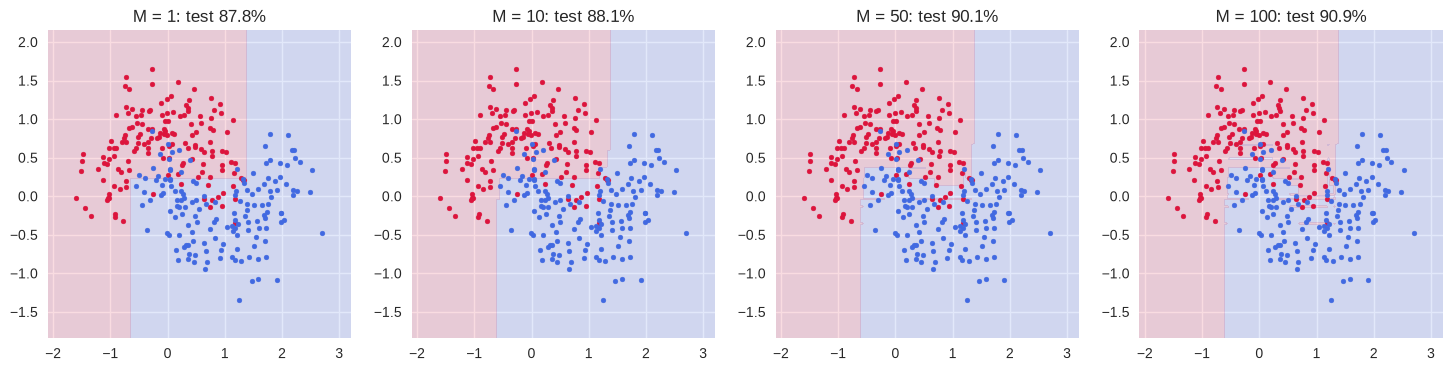

In [12]:
boosting = GradientBoosting(n_trees=100, eta=1.0, max_depth=2).fit(X_moons, y_moons)

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, m in zip(axes, [1, 10, 50, 100]):
    score = accuracy(boosting.predict(X_moons_test, m), y_moons_test)
    plot_regions(ax, lambda X: boosting.predict(X, m), X_moons, y_moons, f"M = {m}: test {score:.1%}")
plt.show()

**Shrinkage** (lecture: "Shrinkage", "The learning rate is a regulariser"). $\eta$ decides how much of each tree enters the model. For $\eta$ = 1, 0.5 and 0.1, 200 trees and the test accuracy after every tree. With $\eta = 1$ the model learns fastest, reaches 91.0% at 80 trees, and then over-fits: 89.6% at 200 trees. Unlike a forest, boosting can over-fit (lecture: "Boosting *can* over-fit"). With $\eta = 0.5$ it learns more slowly, and reaches 91.1% at 188 trees. With $\eta = 0.1$ it is too slow here: 88.3% after 200 trees. A smaller $\eta$ needs more trees.

eta = 1.0: best test accuracy 91.0% at 80 trees, 89.6% at 200 trees
eta = 0.5: best test accuracy 91.1% at 188 trees, 90.9% at 200 trees


eta = 0.1: best test accuracy 88.3% at 166 trees, 88.3% at 200 trees


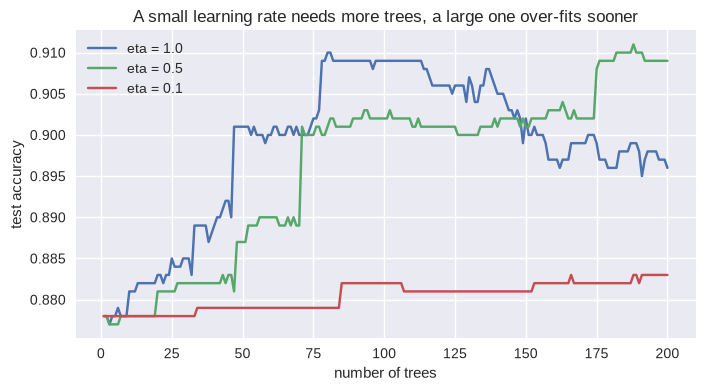

In [13]:
plt.figure(figsize=(8, 4))
for eta in [1.0, 0.5, 0.1]:
    model = GradientBoosting(n_trees=200, eta=eta, max_depth=2).fit(X_moons, y_moons)
    # add the trees one by one, and record the test accuracy after each of them
    F = np.full(len(X_moons_test), model.F0_)
    scores = []
    for tree in model.trees_:
        F = F + eta * tree.predict(X_moons_test)
        scores.append(accuracy((sigmoid(F) > 0.5).astype(int), y_moons_test))
    plt.plot(range(1, 201), scores, label=f"eta = {eta}")
    print(f"eta = {eta}: best test accuracy {max(scores):.1%} at {np.argmax(scores) + 1} trees, {scores[-1]:.1%} at 200 trees")
plt.xlabel("number of trees")
plt.ylabel("test accuracy")
plt.title("A small learning rate needs more trees, a large one over-fits sooner")
plt.legend(loc="upper left")
plt.show()

### Gradient boosting for regression

The same loop predicts numbers, with three changes, since $F$ is now the prediction itself, with no sigmoid: (1) becomes $F_0 = \bar{y}$, the mean of $y$; (2) becomes $r_i = y_i - F(x_i)$; and (5) becomes the prediction $F_M(x)$ itself. (3) and (4) do not change. The residual $y_i - F(x_i)$ is minus the gradient of the squared loss $\frac{1}{2}(y - F)^2$. The data is a noisy sine: every point has 1 column, and $y_i$ is a number.

**Exercise 4 (homework).** Complete `GradientBoostingRegression`: the class of Exercise 3, with these three changes.

In [14]:
class GradientBoostingRegression:
    """Gradient boosting for regression: F is the prediction, and every shallow tree is fitted to the residuals y - F."""

    def __init__(self, n_trees=100, eta=0.1, max_depth=2):
        self.n_trees = n_trees          # number of trees M
        self.eta = eta                  # learning rate
        self.max_depth = max_depth      # depth of every tree

    def fit(self, X, y):
        """Fit the n_trees trees, one after the other."""
        self.F0_ = np.mean(y)                                                    # (1)
        F = np.full(len(y), self.F0_)
        self.trees_ = []
        for _ in range(self.n_trees):
            r = y - F                                                            # (2)
            tree = DecisionTreeRegressor(max_depth=self.max_depth).fit(X, r)    # (3)
            F = F + self.eta * tree.predict(X)                                   # (4)
            self.trees_.append(tree)
        return self

    def predict(self, X, m=None):
        """F_m(x): F_0 plus the first m trees (all of them when m is None)."""
        F = np.full(len(X), self.F0_)
        for tree in self.trees_[:m]:
            F = F + self.eta * tree.predict(X)
        return F                                                                 # (5)

**Check and look:** 100 trees of depth 2 with $\eta = 0.1$, compared with scikit-learn's `GradientBoostingRegressor`, which runs the same loop: if your loop is right, the largest difference between the two predictions is 0. Then the sum of the first 1, 5, 20 and 100 trees. One tree barely moves $F_0$ (test MSE 0.520), and the sum slowly takes the shape of the sine: 0.312 with 5 trees, 0.121 with 20, and 0.107 with 100. The noise has a variance of 0.09, which no model can beat on the test set. With 100 trees the training MSE (0.051) is already far below that, and the fit has spikes: the model has started to follow the noise.

Train MSE 0.051, test MSE 0.107
Largest difference with scikit-learn: 0.00000


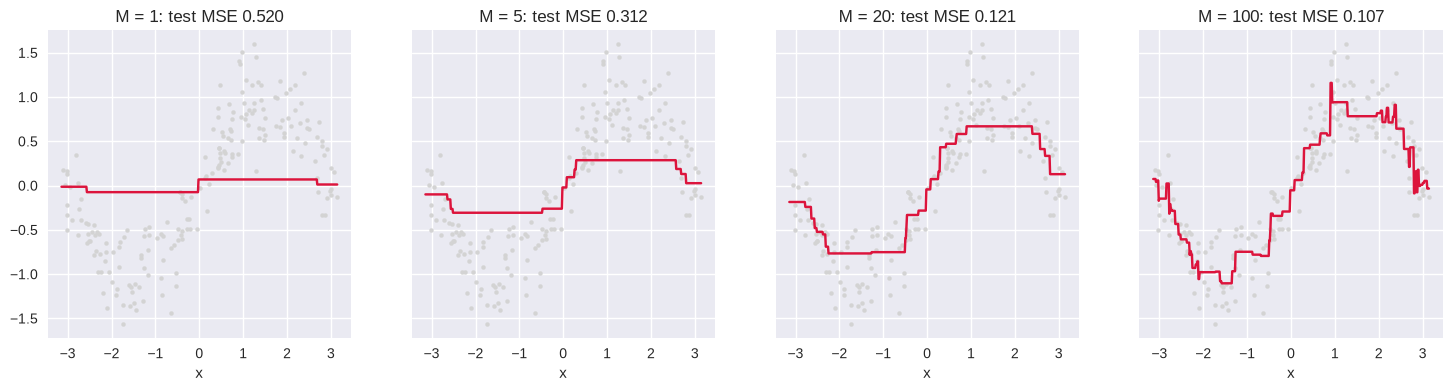

In [15]:
X_wave, y_wave = make_wave(200, seed=0)
X_wave_test, y_wave_test = make_wave(2000, seed=1)

boosting_reg = GradientBoostingRegression(n_trees=100, eta=0.1, max_depth=2).fit(X_wave, y_wave)
sk_boosting = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=2).fit(X_wave, y_wave)
print(f"Train MSE {np.mean((boosting_reg.predict(X_wave) - y_wave) ** 2):.3f}, test MSE {np.mean((boosting_reg.predict(X_wave_test) - y_wave_test) ** 2):.3f}")
print(f"Largest difference with scikit-learn: {np.max(np.abs(boosting_reg.predict(X_wave_test) - sk_boosting.predict(X_wave_test))):.5f}")

grid = np.linspace(-np.pi, np.pi, 500).reshape(-1, 1)
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, m in zip(axes, [1, 5, 20, 100]):
    test_mse = np.mean((boosting_reg.predict(X_wave_test, m) - y_wave_test) ** 2)
    ax.scatter(X_wave, y_wave, s=8, color="lightgray")
    ax.plot(grid, boosting_reg.predict(grid, m), color="crimson")
    ax.set_xlabel("x")
    ax.set_title(f"M = {m}: test MSE {test_mse:.3f}")
plt.show()

### XGBoost

Plain boosting uses only the first derivative of the loss. **XGBoost also uses the second one, and adds a penalty inside the tree** (lecture: "Regularisation inside the tree objective"). The whole method fits in a few numbers.

**What we compute, with the model $F_{m-1}$ already fitted, and one new tree to choose:**
- $g_i$, the **gradient**: the slope of the loss of row $i$ at the current prediction, $g_i = \partial \ell(y_i, F) / \partial F$;
- $h_i$, the **Hessian**: the curvature of the same loss at the same point, $h_i = \partial^2 \ell(y_i, F) / \partial F^2$ (a number, not the tree $h_m$);
- $G = \sum_i g_i$ and $H = \sum_i h_i$, their sums over the rows of a node;
- $w$, the **value** that a leaf outputs, the same for all its rows;
- $\lambda$, a ridge penalty on $w$, and $\gamma$, a fixed cost per leaf.

For the squared loss $\ell = \frac{1}{2}(y - F)^2$: $g_i = F - y$, minus the residual of Exercise 4, and $h_i = 1$.

**The objective.** Expand the loss to second order in the new tree, and add up the rows leaf by leaf (lecture: "Loss simplification for one leaf"). Each leaf $j$ of the $T$ leaves gives a plain quadratic in $w_j$:
$$
\sum_{j=1}^{T} \Big[ G_j w_j + \frac{1}{2} (H_j + \lambda) w_j^2 \Big] + \gamma T .
$$

**The two formulas** that come out of it, the best value of a leaf and the gain of a split (lecture: "Scoring candidate splits"), with $s(G, H) = G^2 / (H + \lambda)$ the **score** of a set of rows:
$$
w^\star = -\frac{G}{H + \lambda}, \qquad
\text{gain} = \frac{1}{2} \Big[ s(G_L, H_L) + s(G_R, H_R) - s(G, H) \Big] - \gamma .
$$

In Section 1, a split was scored by a drop in impurity, from the labels alone. Here it is scored from the derivatives of the loss, so the same formulas work for any loss with two derivatives.

**Exercise 5 (homework).** Complete `grad_hess_squared`, `leaf_value`, `leaf_score` and `split_gain`.

In [16]:
def grad_hess_squared(y, F):
    """Gradient g and Hessian h of the squared loss, two (n,) arrays, for the labels y and the current predictions F."""
    return F - y, np.ones(len(y))


def leaf_value(g, h, lam):
    """Best value w* of a leaf holding the rows with gradients g and Hessians h."""
    G, H = np.sum(g), np.sum(h)
    return -G / (H + lam)


def leaf_score(g, h, lam):
    """Score s(G, H) of the rows with gradients g and Hessians h."""
    G, H = np.sum(g), np.sum(h)
    return G ** 2 / (H + lam)


def split_gain(g, h, left, lam, gamma=0.0):
    """Gain of the split that sends the rows of the boolean array left to the left child."""
    score_left = leaf_score(g[left], h[left], lam)
    score_right = leaf_score(g[~left], h[~left], lam)
    score_node = leaf_score(g, h, lam)
    return (score_left + score_right - score_node) / 2 - gamma

**Check your functions** on small cases where we know the answer, then **against the real XGBoost**. `fit_xgb_stump` fits one XGBoost tree with a single split on the noisy sine, with $\lambda = 5$. The model before this tree predicts `base_score` = 0 for every row, so $F = 0$. We compute the same tree with our formulas, trying every threshold (XGBoost sends the rows with $x < t$ to the left). XGBoost and our formulas give the same tree: the same threshold (-0.0258) and the same two leaf values (-0.6234 and 0.5605). XGBoost is these few formulas, applied again and again.

g: [ 0. -2.  2.] (expected 0, -2, 2) | h: [1. 1. 1.] (expected 1, 1, 1)
w* with lambda 0 and 2: 2.0 1.0 (expected 2.0, 1.0)
Gain of a useless and of a perfect split: 0.0 2.0 (expected 0.0, 2.0)
Threshold, XGBoost: -0.0258, ours: -0.0258
Left leaf, XGBoost: -0.6234, ours: -0.6234
Right leaf, XGBoost: 0.5605, ours: 0.5605


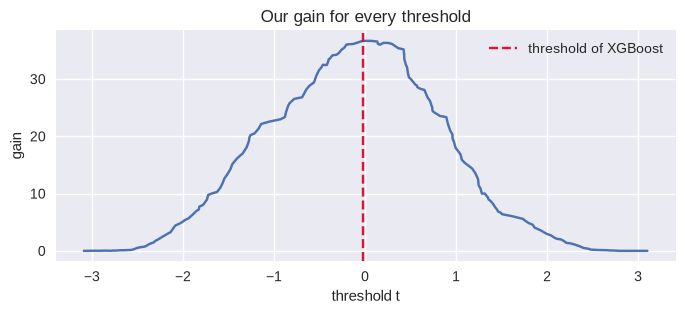

In [17]:
import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostClassifier

g, h = grad_hess_squared(np.array([1., 2., 3.]), np.array([1., 0., 5.]))
print("g:", g, "(expected 0, -2, 2) | h:", h, "(expected 1, 1, 1)")
print("w* with lambda 0 and 2:", leaf_value(np.array([-1., -3.]), np.ones(2), lam=0.0), leaf_value(np.array([-1., -3.]), np.ones(2), lam=2.0), "(expected 2.0, 1.0)")
g, h = np.array([-1., -1., 1., 1.]), np.ones(4)
print("Gain of a useless and of a perfect split:", split_gain(g, h, np.array([True, False, True, False]), lam=0.0),
      split_gain(g, h, np.array([True, True, False, False]), lam=0.0), "(expected 0.0, 2.0)")


def fit_xgb_stump(X, y, objective, base_score, lam):
    """Return the column, the threshold, and the left and right leaf values of one XGBoost tree with a single split."""
    # switched off: shrinkage (eta=1), the floor on H in a leaf (min_child_weight=0), the binning of the columns (exact)
    params = {"objective": objective, "max_depth": 1, "eta": 1.0, "reg_lambda": lam, "base_score": base_score,
              "min_child_weight": 0, "tree_method": "exact"}
    booster = xgb.train(params, xgb.DMatrix(X, label=y), num_boost_round=1)
    node = json.loads(booster.get_dump(dump_format="json")[0])   # the tree, as XGBoost writes it in JSON
    leaves = {child["nodeid"]: child["leaf"] for child in node["children"]}
    return int(node["split"][1:]), node["split_condition"], leaves[node["yes"]], leaves[node["no"]]


lam = 5.0
column, threshold, xgb_left, xgb_right = fit_xgb_stump(X_wave, y_wave, "reg:squarederror", base_score=0.0, lam=lam)
g, h = grad_hess_squared(y_wave, np.zeros(len(y_wave)))   # the model before this tree predicts 0 for every row

# our gain for every threshold, and our leaf values for the threshold of XGBoost
x = X_wave[:, column]
values = np.unique(x)
thresholds = (values[:-1] + values[1:]) / 2
gains = np.array([split_gain(g, h, x < t, lam) for t in thresholds])
left = x < threshold
print(f"Threshold, XGBoost: {threshold:.4f}, ours: {thresholds[np.argmax(gains)]:.4f}")
print(f"Left leaf, XGBoost: {xgb_left:.4f}, ours: {leaf_value(g[left], h[left], lam):.4f}")
print(f"Right leaf, XGBoost: {xgb_right:.4f}, ours: {leaf_value(g[~left], h[~left], lam):.4f}")

plt.figure(figsize=(8, 3))
plt.plot(thresholds, gains)
plt.axvline(threshold, color="crimson", linestyle="--", label="threshold of XGBoost")
plt.xlabel("threshold t")
plt.ylabel("gain")
plt.title("Our gain for every threshold")
plt.legend()
plt.show()

**The penalty $\lambda$** pulls the value of a leaf towards 0. A leaf is a fixed set of rows, so nothing needs to be refitted to see it: we take the left leaf above, and compute $w^\star = -G / (H + \lambda)$ for many values of $\lambda$. For $\lambda \ll H$ the curve is flat: the penalty is invisible next to the total Hessian of the leaf. For $\lambda \gg H$, $w^\star \approx -G / \lambda$ goes to 0. The change happens around $\lambda = H$, and for the squared loss $H$ is just the number of rows in the leaf: a large leaf barely feels the penalty, and a small leaf is pulled strongly towards 0.

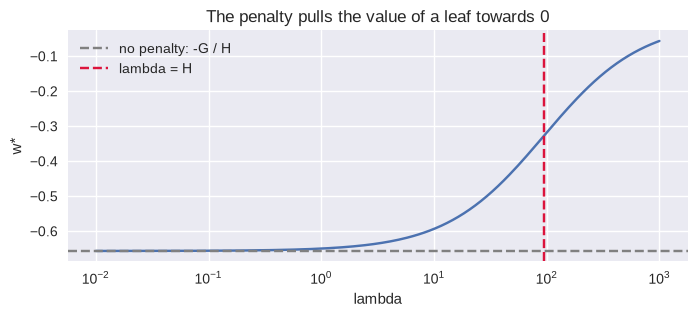

In [18]:
G, H = np.sum(g[left]), np.sum(h[left])
lams = np.logspace(-2, 3, 200)

plt.figure(figsize=(8, 3))
plt.semilogx(lams, -G / (H + lams))
plt.axhline(-G / H, color="gray", linestyle="--", label="no penalty: -G / H")
plt.axvline(H, color="crimson", linestyle="--", label="lambda = H")
plt.xlabel("lambda")
plt.ylabel("w*")
plt.title("The penalty pulls the value of a leaf towards 0")
plt.legend()
plt.show()

### The libraries (no code: run and read)

Each library is the boosting loop with one idea added.

**LightGBM: bin each column once** (lecture: "Bin each feature once", "Scan bin edges, not rows"). Your `best_split` tried every midpoint, which is $n - 1$ candidates per column. LightGBM cuts each column into about 255 quantile bins once, and then only looks at the edges of the bins. Below, the time of 100 trees of depth 6 on 80 000 rows. On binned columns XGBoost is more than 10 times faster than with the exact scan, for the same accuracy (0.910 and 0.911). LightGBM is as fast; its accuracy is lower here (0.898), since its default `num_leaves=31` gives smaller trees than depth 6 allows (up to 64 leaves). The times depend on your machine.

In [19]:
X_timing, y_timing = make_tabular(100_000, n_columns=20, decay=0.9, seed=4)
X_fit, y_fit, X_val, y_val = X_timing[:80_000], y_timing[:80_000], X_timing[80_000:], y_timing[80_000:]

models = {
    "XGBoost, exact": xgb.XGBClassifier(n_estimators=100, max_depth=6, tree_method="exact"),
    "XGBoost, hist": xgb.XGBClassifier(n_estimators=100, max_depth=6, tree_method="hist"),
    "LightGBM": lgb.LGBMClassifier(n_estimators=100, max_depth=6, verbose=-1),
}
for name, model in models.items():
    start_time = time.time()
    model.fit(X_fit, y_fit)
    print(f"{name:15s} {time.time() - start_time:6.2f} s, validation accuracy {model.score(X_val, y_val):.3f}")

XGBoost, exact    5.56 s, validation accuracy 0.911


XGBoost, hist     0.39 s, validation accuracy 0.910


LightGBM          0.38 s, validation accuracy 0.898


**Leaf-wise growth** (lecture: "Leaf-wise growth: spend every split where it pays most"). LightGBM does not grow level by level: at each step it splits the leaf with the largest gain, wherever it is. So its capacity knob is `num_leaves`, not `max_depth`, and it can over-fit a small table quickly. On 1000 rows (`min_child_samples=1` removes the default floor of 20 rows per leaf), the training accuracy is already 1.000 with 31 leaves, and the validation accuracy falls from 0.870 with 4 leaves to 0.695 with 511.

In [20]:
X_small, y_small = make_tabular(1_000, n_columns=20, decay=0.9, seed=5)
X_small_val, y_small_val = make_tabular(1_000, n_columns=20, decay=0.9, seed=3)
for num_leaves in [4, 8, 31, 127, 511]:
    model = lgb.LGBMClassifier(n_estimators=100, num_leaves=num_leaves, min_child_samples=1, verbose=-1).fit(X_small, y_small)
    print(f"num_leaves {num_leaves:3d}: train {model.score(X_small, y_small):.3f}, validation {model.score(X_small_val, y_small_val):.3f}")

num_leaves   4: train 0.960, validation 0.870
num_leaves   8: train 0.999, validation 0.863
num_leaves  31: train 1.000, validation 0.856


num_leaves 127: train 1.000, validation 0.705


num_leaves 511: train 1.000, validation 0.695


**CatBoost: categories without leaking the label** (lecture: "Categories: the target statistic problem", "The encoding leaks the label", "Ordered target statistics: use only what came before"). The categorical column of `make_cat_data` carries no information at all. The obvious encoding replaces each category by the mean of $y$ over the training rows of that category, so a row is part of its own encoding. With 3000 categories for 3000 rows, most categories hold very few rows, and the encoding nearly copies the label: the training accuracy jumps from 0.856 to 0.949, and the test accuracy falls from 0.774 to 0.658.

The fix computes the encoding of each row only from the rows *before* it in a random permutation, with $p$ the global mean of $y$ and $a$ a smoothing weight (the test rows have no "before", so they get the full training statistic):
$$
\hat{x}_i = \frac{\sum_{j \prec i, \; c_j = c_i} y_j + a \, p}{\#\{ j \prec i, \; c_j = c_i \} + a} .
$$
The leak is gone: train 0.858 and test 0.772, the same as with the numeric columns only.

In [21]:
n_categories = 3_000
X_cat, cat, y_cat = make_cat_data(3_000, n_categories, seed=6)
X_cat_test, cat_test, y_cat_test = make_cat_data(3_000, n_categories, seed=7)

# the target statistic of every category, computed on the training rows; a category never seen gets the global mean
prior = np.mean(y_cat)
sums = np.bincount(cat, weights=y_cat, minlength=n_categories)
counts = np.bincount(cat, minlength=n_categories)
encoding = np.where(counts > 0, sums / np.maximum(counts, 1), prior)
X_encoded = np.column_stack([X_cat, encoding[cat]])
X_encoded_test = np.column_stack([X_cat_test, encoding[cat_test]])

# the ordered statistic: the encoding of row i uses only the rows before it
a = 1.0
rng = np.random.RandomState(8)
running_sum, running_count = np.zeros(n_categories), np.zeros(n_categories)
ordered = np.zeros(len(y_cat))
for i in rng.permutation(len(y_cat)):
    c = cat[i]
    ordered[i] = (running_sum[c] + a * prior) / (running_count[c] + a)
    running_sum[c] += y_cat[i]
    running_count[c] += 1
X_ordered = np.column_stack([X_cat, ordered])
X_ordered_test = np.column_stack([X_cat_test, (sums[cat_test] + a * prior) / (counts[cat_test] + a)])

for name, train, test in [("Numeric columns only:     ", X_cat, X_cat_test), ("With the target statistic:", X_encoded, X_encoded_test),
                          ("With the ordered statistic:", X_ordered, X_ordered_test)]:
    tree_cat = DecisionTreeClassifier(max_depth=8, random_state=0).fit(train, y_cat)
    print(f"{name} train {tree_cat.score(train, y_cat):.3f}, test {tree_cat.score(test, y_cat_test):.3f}")

Numeric columns only:      train 0.856, test 0.774
With the target statistic: train 0.949, test 0.658
With the ordered statistic: train 0.858, test 0.772


**CatBoost does all of that by itself**, on a `pandas.DataFrame` whose categorical columns are held as strings and declared in `cat_features`: it does not leak (train 0.859, test 0.794). Then **the three libraries on one dataset** (lecture: "XGBoost, LightGBM, CatBoost"): 50 000 rows split into train, validation and test, with learning rate 0.05 and early stopping after 50 trees without improvement. They are close (test accuracy between 0.91 and 0.92), and LightGBM is the fastest. All three use the objective, the gain and the leaf value of the XGBoost part; what differs is how much of the data they look at, and in what order they spend their splits.

In [22]:
frame = pd.DataFrame({"x1": X_cat[:, 0], "x2": X_cat[:, 1], "x3": X_cat[:, 2], "cat": cat.astype(str)})
frame_test = pd.DataFrame({"x1": X_cat_test[:, 0], "x2": X_cat_test[:, 1], "x3": X_cat_test[:, 2], "cat": cat_test.astype(str)})
model = CatBoostClassifier(iterations=200, depth=6, learning_rate=0.1, cat_features=["cat"],
                           verbose=0, random_seed=0, allow_writing_files=False).fit(frame, y_cat)
print(f"CatBoost on the categorical column: train {model.score(frame, y_cat):.3f}, test {model.score(frame_test, y_cat_test):.3f}")

X_all, y_all = make_tabular(50_000, n_columns=20, decay=0.9, seed=9)
X_fit, y_fit = X_all[:30_000], y_all[:30_000]
X_val, y_val = X_all[30_000:40_000], y_all[30_000:40_000]
X_final, y_final = X_all[40_000:], y_all[40_000:]

start_time = time.time()
model = xgb.XGBClassifier(n_estimators=2000, learning_rate=0.05, early_stopping_rounds=50, eval_metric="logloss")
model.fit(X_fit, y_fit, eval_set=[(X_val, y_val)], verbose=False)
print(f"XGBoost:  {model.best_iteration} trees, {time.time() - start_time:.1f} s, test accuracy {model.score(X_final, y_final):.3f}")

start_time = time.time()
model = lgb.LGBMClassifier(n_estimators=2000, learning_rate=0.05, verbose=-1)
model.fit(X_fit, y_fit, eval_X=X_val, eval_y=y_val, callbacks=[lgb.early_stopping(50, verbose=False)])
print(f"LightGBM: {model.best_iteration_} trees, {time.time() - start_time:.1f} s, test accuracy {model.score(X_final, y_final):.3f}")

start_time = time.time()
model = CatBoostClassifier(iterations=2000, learning_rate=0.05, early_stopping_rounds=50, verbose=0, random_seed=0, allow_writing_files=False)
model.fit(X_fit, y_fit, eval_set=(X_val, y_val))
print(f"CatBoost: {model.get_best_iteration()} trees, {time.time() - start_time:.1f} s, test accuracy {model.score(X_final, y_final):.3f}")

CatBoost on the categorical column: train 0.859, test 0.794


XGBoost:  1147 trees, 3.1 s, test accuracy 0.917


LightGBM: 981 trees, 2.1 s, test accuracy 0.916


CatBoost: 1841 trees, 9.6 s, test accuracy 0.921
